In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1e9, 2
    ))
else:
    print("No GPU assigned. Do not start full training yet.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [2]:
from google.colab import files

uploaded = files.upload()

Saving ScratchGPT-Colab.zip to ScratchGPT-Colab.zip


In [7]:
from pathlib import Path, PurePosixPath
import shutil
import zipfile

archive = Path("/content/ScratchGPT-Colab.zip")
project_dir = Path("/content/ScratchGPT")

# Rebuild the extraction directory from scratch.
if project_dir.exists():
    shutil.rmtree(project_dir)

project_dir.mkdir(parents=True)

with zipfile.ZipFile(archive, "r") as z:
    entries = []

    for member in z.infolist():
        name = member.filename.replace("\\", "/").strip("/")

        if not name:
            continue

        relative_path = PurePosixPath(name)

        if relative_path.is_absolute() or ".." in relative_path.parts:
            raise ValueError(f"Unsafe archive path: {member.filename}")

        entries.append((member, relative_path))

    # Identify directories using all archive paths, not only ZIP metadata.
    directories = set()

    for member, relative_path in entries:
        parts = relative_path.parts

        for i in range(1, len(parts)):
            directories.add(PurePosixPath(*parts[:i]))

        if member.is_dir():
            directories.add(relative_path)

    # Create every directory first.
    for relative_path in sorted(directories, key=lambda p: len(p.parts)):
        (project_dir / Path(*relative_path.parts)).mkdir(
            parents=True, exist_ok=True
        )

    # Extract files only after the directory structure exists.
    for member, relative_path in entries:
        if relative_path in directories:
            continue

        destination = project_dir / Path(*relative_path.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)

        with z.open(member) as source, destination.open("wb") as target:
            shutil.copyfileobj(source, target)

required_files = [
    "pyproject.toml",
    "src/scratchgpt/model.py",
    "src/scratchgpt/checkpoint.py",
    "src/scratchgpt/tokenizer.py",
    "scripts/train.py",
    "data/processed/tokenizer.json",
    "data/raw/train/tinystories_train.txt",
    "data/raw/validation/tinystories_validation.txt",
]

for relative_path in required_files:
    path = project_dir / relative_path
    assert path.is_file(), f"Missing required file: {relative_path}"
    print(f"OK: {relative_path} ({path.stat().st_size:,} bytes)")

print("\nExtraction and required-file checks passed.")

OK: pyproject.toml (809 bytes)
OK: src/scratchgpt/model.py (3,907 bytes)
OK: src/scratchgpt/checkpoint.py (4,087 bytes)
OK: src/scratchgpt/tokenizer.py (11,429 bytes)
OK: scripts/train.py (14,439 bytes)
OK: data/processed/tokenizer.json (408,652 bytes)
OK: data/raw/train/tinystories_train.txt (8,712,527 bytes)
OK: data/raw/validation/tinystories_validation.txt (406,231 bytes)

Extraction and required-file checks passed.


In [8]:
from pathlib import Path
import json

project_dir = Path("/content/ScratchGPT")

train_file = project_dir / "data/raw/train/tinystories_train.txt"
validation_file = project_dir / "data/raw/validation/tinystories_validation.txt"
tokenizer_file = project_dir / "data/processed/tokenizer.json"

train_text = train_file.read_text(encoding="utf-8")
validation_text = validation_file.read_text(encoding="utf-8")
tokenizer_data = json.loads(tokenizer_file.read_text(encoding="utf-8"))

print("Training file:")
print("  Bytes:", train_file.stat().st_size)
print("  Characters:", len(train_text))
print("  Non-empty lines:", sum(bool(line.strip()) for line in train_text.splitlines()))

print("\nValidation file:")
print("  Bytes:", validation_file.stat().st_size)
print("  Characters:", len(validation_text))
print("  Non-empty lines:", sum(bool(line.strip()) for line in validation_text.splitlines()))

print("\nTokenizer JSON top-level keys:", list(tokenizer_data.keys()))
print("Train and validation files are separate:", train_file != validation_file)

Training file:
  Bytes: 8712527
  Characters: 8694761
  Non-empty lines: 52631

Validation file:
  Bytes: 406231
  Characters: 406081
  Non-empty lines: 2185

Tokenizer JSON top-level keys: ['format', 'vocab_size', 'merges']
Train and validation files are separate: True


In [9]:
%cd /content/ScratchGPT
%pip install -e ".[training]"

/content/ScratchGPT
Obtaining file:///content/ScratchGPT
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for scratchgpt (pyproject.toml) ... done
  Created wheel for scratchgpt: filename=scratchgpt-0.1.0-0.editable-py3-none-any.whl size=1374 sha256=37c8237fd47c316dee8638adffdc7df2b5b7a1a5c382fe93df16e72f572b1a2c
  Stored in directory: /tmp/pip-ephem-wheel-cache-zbzol9fh/wheels/13/52/b0/9346e5ebea07cb9fa3addcd7e8b11f78ce4dec532c9aac95e2
Successfully built scratchgpt


In [11]:
%cd /content/ScratchGPT

from pathlib import Path
import importlib.metadata as metadata
import importlib.util
import sys

print("Python:", sys.executable)
print("Project directory:", Path.cwd())

print("\nPackage files:")
package_dir = Path("src/scratchgpt")
if package_dir.exists():
    for path in sorted(package_dir.iterdir()):
        print(f"  {path.name} ({'directory' if path.is_dir() else 'file'})")
else:
    print("  ERROR: src/scratchgpt does not exist")

print("\nPackage initialization file:")
print("  src/scratchgpt/__init__.py exists:", (package_dir / "__init__.py").is_file())

print("\nPython source path:")
print("  src in sys.path:", str(Path("src").resolve()) in sys.path)

print("\nInstalled distribution:")
try:
    dist = metadata.distribution("scratchgpt")
    print("  Version:", dist.version)
    print("  Installation metadata:", dist._path)
    print("  Installed package files:")
    for file in (dist.files or []):
        if "scratchgpt" in str(file).lower():
            print("   ", file)
except metadata.PackageNotFoundError:
    print("  Distribution not found")

print("\nImport lookup:")
print("  scratchgpt:", importlib.util.find_spec("scratchgpt"))

print("\n--- pyproject.toml ---")
print(Path("pyproject.toml").read_text(encoding="utf-8"))

/content/ScratchGPT
Python: /usr/bin/python3
Project directory: /content/ScratchGPT

Package files:
  __init__.py (file)
  __pycache__ (directory)
  attention.py (file)
  checkpoint.py (file)
  config.py (file)
  dataloaders.py (file)
  dataset.py (file)
  embeddings.py (file)
  generation.py (file)
  loss.py (file)
  model.py (file)
  tokenizer.py (file)
  training.py (file)
  transformer_block.py (file)

Package initialization file:
  src/scratchgpt/__init__.py exists: True

Python source path:
  src in sys.path: False

Installed distribution:
  Version: 0.1.0
  Installation metadata: /usr/local/lib/python3.13/dist-packages/scratchgpt-0.1.0.dist-info
  Installed package files:
    __editable__.scratchgpt-0.1.0.pth
    scratchgpt-0.1.0.dist-info/INSTALLER
    scratchgpt-0.1.0.dist-info/METADATA
    scratchgpt-0.1.0.dist-info/RECORD
    scratchgpt-0.1.0.dist-info/REQUESTED
    scratchgpt-0.1.0.dist-info/WHEEL
    scratchgpt-0.1.0.dist-info/direct_url.json
    scratchgpt-0.1.0.dist-info

In [12]:
%cd /content/ScratchGPT

import sys
from pathlib import Path

project_dir = Path("/content/ScratchGPT").resolve()
src_dir = project_dir / "src"

assert (src_dir / "scratchgpt" / "__init__.py").is_file(), (
    "ScratchGPT package initialization file is missing."
)

# Make the project's src directory visible to this notebook's Python.
src_path = str(src_dir)
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import scratchgpt
import torch

print("ScratchGPT import:", scratchgpt.__file__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GiB",
    )

/content/ScratchGPT
ScratchGPT import: /content/ScratchGPT/src/scratchgpt/__init__.py
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GiB


In [13]:
import inspect
import torch

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel

print("GPTConfig signature:")
print(inspect.signature(GPTConfig))

print("\nGPTModel signature:")
print(inspect.signature(GPTModel))

print("\nModel source:")
print(inspect.getfile(GPTModel))

GPTConfig signature:
(vocab_size: int = 8192, context_length: int = 256, embedding_dim: int = 320, num_layers: int = 6, num_heads: int = 8, feed_forward_dim: int = 1280, dropout: float = 0.1) -> None

GPTModel signature:
(config: scratchgpt.config.GPTConfig) -> None

Model source:
/content/ScratchGPT/src/scratchgpt/model.py


In [14]:
import gc
import torch

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel

assert torch.cuda.is_available(), "CUDA is unavailable."

device = torch.device("cuda")

# Create the configured model from random initialization.
config = GPTConfig(
    vocab_size=8192,
    context_length=256,
    embedding_dim=320,
    num_layers=6,
    num_heads=8,
    feed_forward_dim=1280,
    dropout=0.1,
)

model = GPTModel(config).to(device)
model.eval()

parameter_count = sum(p.numel() for p in model.parameters())

print("ScratchGPT GPU validation")
print("=" * 40)
print(f"Device: {device}")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Parameters: {parameter_count:,}")
print(f"Model parameter memory: {sum(p.numel() * p.element_size() for p in model.parameters()) / 1024**2:.2f} MiB")

# Test with a small batch of valid token IDs.
input_ids = torch.randint(
    low=0,
    high=config.vocab_size,
    size=(2, 32),
    dtype=torch.long,
    device=device,
)

with torch.no_grad():
    logits = model(input_ids)

torch.cuda.synchronize()

print(f"\nInput shape: {tuple(input_ids.shape)}")
print(f"Output type: {type(logits).__name__}")

if isinstance(logits, torch.Tensor):
    print(f"Output shape: {tuple(logits.shape)}")
    print(f"Output device: {logits.device}")
    print(f"All output values finite: {torch.isfinite(logits).all().item()}")

    assert logits.shape == (2, 32, config.vocab_size), (
        f"Unexpected output shape: {tuple(logits.shape)}"
    )
    assert torch.isfinite(logits).all(), "Model produced NaN or infinite values."
else:
    raise TypeError(f"Expected Tensor output, got {type(logits).__name__}")

print(f"\nGPU allocated: {torch.cuda.memory_allocated() / 1024**3:.3f} GiB")
print(f"GPU reserved: {torch.cuda.memory_reserved() / 1024**3:.3f} GiB")
print("\nGPU forward-pass test PASSED.")

ScratchGPT GPU validation
Device: cuda
GPU: Tesla T4
Parameters: 10,101,760
Model parameter memory: 38.54 MiB

Input shape: (2, 32)
Output type: Tensor
Output shape: (2, 32, 8192)
Output device: cuda:0
All output values finite: True

GPU allocated: 0.049 GiB
GPU reserved: 0.055 GiB

GPU forward-pass test PASSED.


In [15]:
from pathlib import Path
import inspect
import json
import torch

from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.dataset import NextTokenDataset
from scratchgpt.dataloaders import create_dataloaders

project_dir = Path("/content/ScratchGPT")
tokenizer_path = project_dir / "data/processed/tokenizer.json"
train_path = project_dir / "data/raw/train/tinystories_train.txt"
validation_path = project_dir / "data/raw/validation/tinystories_validation.txt"

print("Tokenizer loader:", inspect.signature(ByteBPETokenizer.load))
print("Dataset constructor:", inspect.signature(NextTokenDataset))
print("Dataloader function:", inspect.signature(create_dataloaders))

print("\nDataset source:")
print(inspect.getsource(NextTokenDataset))

print("\nDataloader source:")
print(inspect.getsource(create_dataloaders))

Tokenizer loader: (path: str | pathlib._local.Path) -> 'ByteBPETokenizer'
Dataset constructor: (token_ids: list[int], sequence_length: int, stride: int = 1) -> None
Dataloader function: (train_dataset: scratchgpt.dataset.NextTokenDataset, validation_dataset: scratchgpt.dataset.NextTokenDataset, batch_size: int = 8, seed: int = 42, num_workers: int = 0) -> tuple[torch.utils.data.dataloader.DataLoader, torch.utils.data.dataloader.DataLoader]

Dataset source:
class NextTokenDataset(Dataset):
    """Create fixed-length input and target sequences for next-token prediction."""

    def __init__(
        self,
        token_ids: list[int],
        sequence_length: int,
        stride: int = 1,
    ) -> None:
        if type(sequence_length) is not int or sequence_length < 1:
            raise ValueError("sequence_length must be a positive integer")

        if type(stride) is not int or stride < 1:
            raise ValueError("stride must be a positive integer")

        if any(type(token_id

In [16]:
from pathlib import Path
import torch

from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.dataset import NextTokenDataset
from scratchgpt.dataloaders import create_dataloaders

project_dir = Path("/content/ScratchGPT")

# 1. Load the existing tokenizer.
tokenizer = ByteBPETokenizer.load(
    project_dir / "data/processed/tokenizer.json"
)

print("Tokenizer loaded.")
print("Vocabulary size:", tokenizer.vocab_size)

assert tokenizer.vocab_size == 8192, (
    f"Expected vocabulary size 8192, got {tokenizer.vocab_size}"
)

# 2. Read and encode the separate training and validation files.
train_text = (
    project_dir / "data/raw/train/tinystories_train.txt"
).read_text(encoding="utf-8")

validation_text = (
    project_dir / "data/raw/validation/tinystories_validation.txt"
).read_text(encoding="utf-8")

train_ids = tokenizer.encode(train_text)
validation_ids = tokenizer.encode(validation_text)

print("\nEncoded token counts:")
print("Training:", len(train_ids))
print("Validation:", len(validation_ids))

assert len(train_ids) > 256
assert len(validation_ids) > 256
assert min(train_ids) >= 0 and max(train_ids) < tokenizer.vocab_size
assert min(validation_ids) >= 0 and max(validation_ids) < tokenizer.vocab_size

# 3. Verify next-token shifting.
test_dataset = NextTokenDataset(
    token_ids=[10, 20, 30, 40, 50],
    sequence_length=3,
    stride=1,
)

x, y = test_dataset[0]

print("\nNext-token target test:")
print("Input: ", x.tolist())
print("Target:", y.tolist())

assert x.tolist() == [10, 20, 30]
assert y.tolist() == [20, 30, 40]

# 4. Create the real project datasets and dataloaders.
sequence_length = 256
batch_size = 8

train_dataset = NextTokenDataset(
    train_ids,
    sequence_length=sequence_length,
    stride=sequence_length,
)

validation_dataset = NextTokenDataset(
    validation_ids,
    sequence_length=sequence_length,
    stride=sequence_length,
)

train_loader, validation_loader = create_dataloaders(
    train_dataset=train_dataset,
    validation_dataset=validation_dataset,
    batch_size=batch_size,
    seed=42,
    num_workers=0,
)

print("\nReal dataset sizes:")
print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

# 5. Check actual batches.
batch_x, batch_y = next(iter(train_loader))

print("\nFirst training batch:")
print("Input shape:", tuple(batch_x.shape))
print("Target shape:", tuple(batch_y.shape))
print("Input dtype:", batch_x.dtype)
print("Target dtype:", batch_y.dtype)

assert batch_x.shape == (batch_size, sequence_length)
assert batch_y.shape == (batch_size, sequence_length)
assert batch_x.dtype == torch.long
assert batch_y.dtype == torch.long
assert torch.equal(batch_x[:, 1:], batch_y[:, :-1])

# 6. Confirm a real batch can run through the GPU model.
from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel

device = torch.device("cuda")
config = GPTConfig(vocab_size=tokenizer.vocab_size)
model = GPTModel(config).to(device).eval()

with torch.no_grad():
    logits = model(batch_x.to(device))

torch.cuda.synchronize()

print("\nGPU batch test:")
print("Logits shape:", tuple(logits.shape))
print("All logits finite:", torch.isfinite(logits).all().item())

assert logits.shape == (batch_size, sequence_length, tokenizer.vocab_size)
assert torch.isfinite(logits).all()

print("\nALL TOKENIZER, DATASET, AND GPU BATCH CHECKS PASSED.")

Tokenizer loaded.
Vocabulary size: 8192

Encoded token counts:
Training: 2133488
Validation: 99450

Next-token target test:
Input:  [10, 20, 30]
Target: [20, 30, 40]

Real dataset sizes:
Training examples: 8333
Validation examples: 388
Training batches: 1042
Validation batches: 49

First training batch:
Input shape: (8, 256)
Target shape: (8, 256)
Input dtype: torch.int64
Target dtype: torch.int64

GPU batch test:
Logits shape: (8, 256, 8192)
All logits finite: True

ALL TOKENIZER, DATASET, AND GPU BATCH CHECKS PASSED.


In [17]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train.py \
    --epochs 1 \
    --max-train-batches 10 \
    --max-validation-batches 5 \
    --checkpoint /content/scratchgpt_benchmark.pt \
    --history /content/scratchgpt_benchmark_history.json

/content/ScratchGPT
Loading and encoding training data...
Loading and encoding validation data...

ScratchGPT training
Device: cuda
Parameters: 10,101,760
Vocabulary: 8,192
Training tokens: 2,133,488
Validation tokens: 99,450
Training examples: 8,333
Validation examples: 388
Training batches per full epoch: 1,042
Validation batches: 49
Batch size: 8
Sequence length: 256
Stride: 256
Target completed epochs: 1
Already completed epochs: 0
Learning rate: 0.0003
Resume enabled: False

Epoch 1/1 | status=PARTIAL | train_batches=10/1042 | validation_batches=5/49 | train_loss=8.0555 | validation_loss=7.3373 | time=1.1s
Checkpoint saved: /content/scratchgpt_benchmark.pt
History saved: /content/scratchgpt_benchmark_history.json
Partial run recorded. This checkpoint cannot be resumed as though the epoch were complete.

Training run finished.


In [18]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

output_dir = Path("/content/drive/MyDrive/ScratchGPT-training")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "scratchgpt.pt"
history_path = output_dir / "training_history.json"

print("Persistent output directory:", output_dir)
print("Checkpoint path:", checkpoint_path)
print("History path:", history_path)
print("Checkpoint already exists:", checkpoint_path.exists())
print("History already exists:", history_path.exists())

Mounted at /content/drive
Persistent output directory: /content/drive/MyDrive/ScratchGPT-training
Checkpoint path: /content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt
History path: /content/drive/MyDrive/ScratchGPT-training/training_history.json
Checkpoint already exists: False
History already exists: False


In [19]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train.py --help

/content/ScratchGPT
usage: train.py [-h] [--epochs EPOCHS] [--batch-size BATCH_SIZE]
                [--sequence-length SEQUENCE_LENGTH] [--stride STRIDE]
                [--learning-rate LEARNING_RATE] [--seed SEED]
                [--num-workers NUM_WORKERS] [--device {auto,cpu,cuda}]
                [--max-train-batches MAX_TRAIN_BATCHES]
                [--max-validation-batches MAX_VALIDATION_BATCHES] [--resume]
                [--tokenizer TOKENIZER] [--train-file TRAIN_FILE]
                [--validation-file VALIDATION_FILE] [--checkpoint CHECKPOINT]
                [--history HISTORY]

Train ScratchGPT on TinyStories.

options:
  -h, --help            show this help message and exit
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --sequence-length SEQUENCE_LENGTH
  --stride STRIDE
  --learning-rate LEARNING_RATE
  --seed SEED
  --num-workers NUM_WORKERS
  --device {auto,cpu,cuda}
  --max-train-batches MAX_TRAIN_BATCHES
                        Limit training batches per epoch for

In [20]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train.py \
    --epochs 3 \
    --batch-size 8 \
    --sequence-length 256 \
    --stride 256 \
    --learning-rate 0.0003 \
    --seed 42 \
    --device cuda \
    --checkpoint /content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt \
    --history /content/drive/MyDrive/ScratchGPT-training/training_history.json

/content/ScratchGPT
Loading and encoding training data...
Loading and encoding validation data...

ScratchGPT training
Device: cuda
Parameters: 10,101,760
Vocabulary: 8,192
Training tokens: 2,133,488
Validation tokens: 99,450
Training examples: 8,333
Validation examples: 388
Training batches per full epoch: 1,042
Validation batches: 49
Batch size: 8
Sequence length: 256
Stride: 256
Target completed epochs: 3
Already completed epochs: 0
Learning rate: 0.0003
Resume enabled: False

Epoch 1/3 | status=complete | train_batches=1042/1042 | validation_batches=49/49 | train_loss=4.0399 | validation_loss=3.1822 | time=66.2s
Checkpoint saved: /content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt
History saved: /content/drive/MyDrive/ScratchGPT-training/training_history.json
Epoch 2/3 | status=complete | train_batches=1042/1042 | validation_batches=49/49 | train_loss=3.1402 | validation_loss=2.7337 | time=65.9s
Checkpoint saved: /content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt
History

In [22]:
from pathlib import Path
import ast
import json
import inspect

from scratchgpt import generation, checkpoint, tokenizer

project_dir = Path("/content/ScratchGPT")

def inspect_python_module(module, label):
    print(f"\n{'=' * 60}")
    print(label)
    print("=" * 60)
    print("File:", inspect.getfile(module))

    source = inspect.getsource(module)
    print("\nSource code:\n")
    print(source)

    tree = ast.parse(source)
    functions = [
        node.name
        for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ]
    classes = [
        node.name
        for node in tree.body
        if isinstance(node, ast.ClassDef)
    ]

    print("\nFunctions:", functions)
    print("Classes:", classes)

inspect_python_module(generation, "GENERATION MODULE")
inspect_python_module(checkpoint, "CHECKPOINT MODULE")

print("\n" + "=" * 60)
print("TOKENIZER API")
print("=" * 60)

print("Tokenizer class:", tokenizer.ByteBPETokenizer)
print("Available methods:", [
    name for name in dir(tokenizer.ByteBPETokenizer)
    if not name.startswith("_")
])

print("\n" + "=" * 60)
print("TRAINING HISTORY")
print("=" * 60)

history_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/training_history.json"
)
assert history_path.is_file(), f"History file missing: {history_path}"

with history_path.open("r", encoding="utf-8") as file:
    history_data = json.load(file)

print(json.dumps(history_data, indent=2)[:12000])

print("\n" + "=" * 60)
print("CHECKPOINT EXISTS")
print("=" * 60)

checkpoint_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt"
)
assert checkpoint_path.is_file(), f"Checkpoint missing: {checkpoint_path}"
print("Path:", checkpoint_path)
print("Size:", f"{checkpoint_path.stat().st_size:,} bytes")


GENERATION MODULE
File: /content/ScratchGPT/src/scratchgpt/generation.py

Source code:

"""Autoregressive text-generation utilities for ScratchGPT."""

import math

import torch
from torch import nn


def generate_tokens(
    model: nn.Module,
    input_ids: torch.Tensor,
    max_new_tokens: int,
    temperature: float = 1.0,
    top_k: int | None = None,
    do_sample: bool = True,
) -> torch.Tensor:
    """Generate tokens autoregressively from an initial sequence.

    Args:
        model: A model that returns logits with shape
            (batch_size, sequence_length, vocabulary_size).
        input_ids: Initial token IDs with shape (batch_size, sequence_length).
        max_new_tokens: Maximum number of tokens to append.
        temperature: Sampling temperature. Must be finite and positive.
        top_k: If provided, sample only from the top-k token candidates.
        do_sample: If True, sample probabilistically. Otherwise, use greedy
            decoding by selecting the highe

In [23]:
import json
from pathlib import Path

import torch

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens

# Paths to the actual trained artifacts.
project_dir = Path("/content/ScratchGPT")
checkpoint_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt"
)
history_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/training_history.json"
)
tokenizer_path = project_dir / "data/processed/tokenizer.json"

assert checkpoint_path.is_file(), "Trained checkpoint is missing."
assert history_path.is_file(), "Training history is missing."

# 1. Verify the saved training history.
with history_path.open("r", encoding="utf-8") as file:
    history = json.load(file)

assert len(history) == 3
assert all(record["epoch_complete"] for record in history)

print("Completed epochs:", len(history))
print("Final validation loss:", history[-1]["validation_loss"])

# 2. Load the saved checkpoint.
# weights_only=True avoids loading arbitrary Python objects.
saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert saved_checkpoint["epoch"] == 3, (
    f"Expected checkpoint epoch 3, got {saved_checkpoint['epoch']}"
)

# Reconstruct the exact saved model configuration.
config = GPTConfig(**saved_checkpoint["config"])
model = GPTModel(config)
model.load_state_dict(saved_checkpoint["model_state_dict"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

parameter_count = sum(p.numel() for p in model.parameters())

print("\nTrained model loaded successfully.")
print("Checkpoint epoch:", saved_checkpoint["epoch"])
print("Parameters:", f"{parameter_count:,}")
print("Device:", device)

assert parameter_count == 10_101_760

# 3. Load the same tokenizer used during training.
tokenizer = ByteBPETokenizer.load(tokenizer_path)

assert tokenizer.vocab_size == config.vocab_size

# 4. Generate from a prompt.
prompt = "Once upon a time"
prompt_ids = tokenizer.encode(prompt)

assert len(prompt_ids) > 0
assert len(prompt_ids) <= config.context_length

input_ids = torch.tensor(
    [prompt_ids],
    dtype=torch.long,
    device=device,
)

# Fix the random seed so this sampling run is reproducible
# under the same software and hardware environment.
torch.manual_seed(1234)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1234)

with torch.inference_mode():
    output_ids = generate_tokens(
        model=model,
        input_ids=input_ids,
        max_new_tokens=120,
        temperature=0.8,
        top_k=40,
        do_sample=True,
    )

generated_ids = output_ids[0].tolist()
generated_text = tokenizer.decode(generated_ids)

print("\n" + "=" * 60)
print("SCRATCHGPT GENERATED STORY")
print("=" * 60)
print(generated_text)
print("=" * 60)

print("Prompt tokens:", len(prompt_ids))
print("New tokens generated:", len(generated_ids) - len(prompt_ids))
print("Total tokens:", len(generated_ids))

Completed epochs: 3
Final validation loss: 2.508643968818114

Trained model loaded successfully.
Checkpoint epoch: 3
Parameters: 10,101,760
Device: cuda

SCRATCHGPT GENERATED STORY
Once upon a time, there was a little girl named Lily. She loved to play outside with her friends. One day, they got so badly. They started to run and play.

But Lily's friend, Timmy, came over to take a break where he saw. He walked up to it when Timmy's friend, asked Billy, "Let's play hide and seek!"

But Timmy didn't listen. He wanted to eat the game but instead of instead he was too fast. So, she gave Timmy a big hug and then gave him a towel. Timmy was grateful to his friend Billy and helped
Prompt tokens: 4
New tokens generated: 120
Total tokens: 124


In [24]:
from pathlib import Path
import json
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt"
)
history_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/training_history.json"
)

assert checkpoint_path.is_file(), "Checkpoint missing!"
assert history_path.is_file(), "Training history missing!"

with history_path.open("r", encoding="utf-8") as f:
    history = json.load(f)

assert len(history) == 3
assert all(row["epoch_complete"] for row in history)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["epoch"] == 3

print("Baseline verified")
print(f"Completed epochs: {len(history)}")
print(f"Checkpoint epoch: {checkpoint['epoch']}")
print(f"Checkpoint size: {checkpoint_path.stat().st_size:,} bytes")
print(f"Final validation loss: {history[-1]['validation_loss']:.4f}")

Baseline verified
Completed epochs: 3
Checkpoint epoch: 3
Checkpoint size: 121,329,796 bytes
Final validation loss: 2.5086


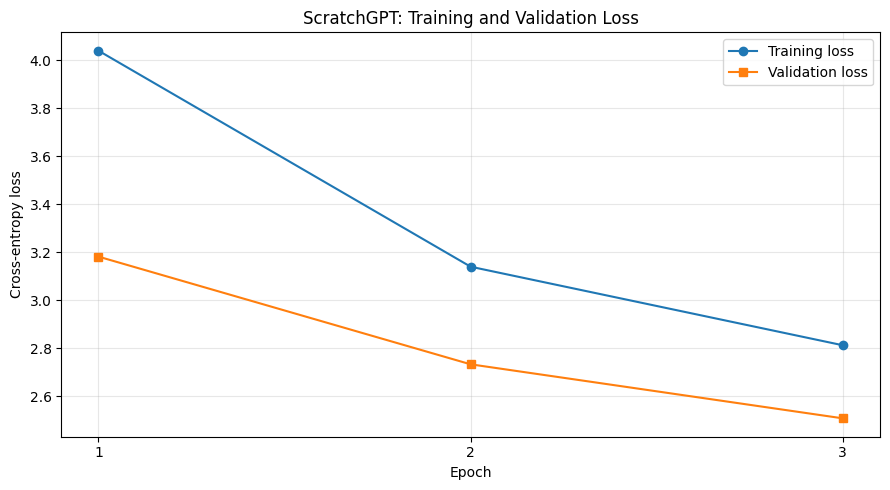

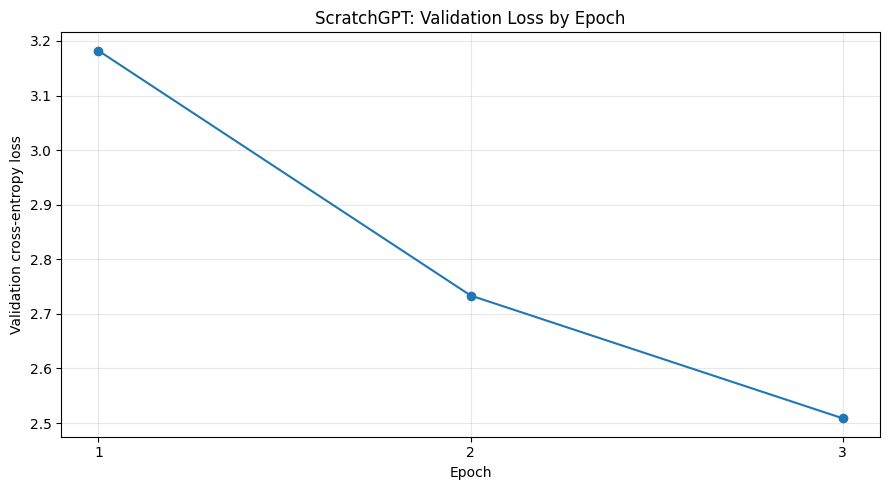

Saved genuine training graphs:
/content/drive/MyDrive/ScratchGPT-training/evaluation/loss_curves.png
/content/drive/MyDrive/ScratchGPT-training/evaluation/validation_loss.png


In [25]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

history_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/training_history.json"
)
output_dir = Path(
    "/content/drive/MyDrive/ScratchGPT-training/evaluation"
)
output_dir.mkdir(parents=True, exist_ok=True)

with history_path.open("r", encoding="utf-8") as f:
    history = json.load(f)

assert len(history) >= 1
assert all(row.get("epoch_complete") for row in history)

epochs = [row["epoch"] for row in history]
train_losses = [row["train_loss"] for row in history]
val_losses = [row["validation_loss"] for row in history]

# Graph 1: training and validation loss
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, marker="o", label="Training loss")
plt.plot(epochs, val_losses, marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ScratchGPT: Training and Validation Loss")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

loss_plot_path = output_dir / "loss_curves.png"
plt.savefig(loss_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# Graph 2: validation loss only
plt.figure(figsize=(9, 5))
plt.plot(epochs, val_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("ScratchGPT: Validation Loss by Epoch")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.tight_layout()

val_plot_path = output_dir / "validation_loss.png"
plt.savefig(val_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Saved genuine training graphs:")
print(loss_plot_path)
print(val_plot_path)

In [26]:
import sys
from pathlib import Path
import torch

project_dir = Path("/content/ScratchGPT").resolve()
src_dir = project_dir / "src"

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens

checkpoint_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/scratchgpt.pt"
)
tokenizer_path = project_dir / "data/processed/tokenizer.json"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

config = GPTConfig(**checkpoint["config"])
model = GPTModel(config)
model.load_state_dict(checkpoint["model_state_dict"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

tokenizer = ByteBPETokenizer.load(tokenizer_path)

prompts = [
    "Once upon a time",
    "A little boy went to the forest",
    "One day, a rabbit found",
    "Lily wanted to help her friend",
]

for prompt_index, prompt in enumerate(prompts):
    prompt_ids = tokenizer.encode(prompt)
    input_ids = torch.tensor(
        [prompt_ids], dtype=torch.long, device=device
    )

    print("\n" + "=" * 70)
    print(f"PROMPT {prompt_index + 1}: {prompt}")
    print("=" * 70)

    # Greedy decoding: selects the highest-probability next token.
    with torch.inference_mode():
        greedy_ids = generate_tokens(
            model=model,
            input_ids=input_ids,
            max_new_tokens=100,
            do_sample=False,
        )

    print("\n[GREEDY DECODING]")
    print(tokenizer.decode(greedy_ids[0].tolist()))

    # Sampling: allows variation among likely next tokens.
    torch.manual_seed(1000 + prompt_index)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(1000 + prompt_index)

    with torch.inference_mode():
        sampled_ids = generate_tokens(
            model=model,
            input_ids=input_ids,
            max_new_tokens=100,
            temperature=0.8,
            top_k=40,
            do_sample=True,
        )

    print("\n[SAMPLED DECODING]")
    print(tokenizer.decode(sampled_ids[0].tolist()))


PROMPT 1: Once upon a time

[GREEDY DECODING]
Once upon a time, there was a little girl named Lily. She loved to play outside and play with her friends. One day, Lily's friend Billy came over to play. Timmy was so happy to play with Timmy.

Timmy's friend Billy came over to play. Timmy was so happy to play with Timmy. Timmy's friend Billy said, "Timmy, you can play with me?"

Timmy's friend Billy said, "Yes, but be careful. We can play together."

Timmy's

[SAMPLED DECODING]
Once upon a time, there was a little girl named Lily. She loved to play outside with her toys. One day, Lily's mom said, "Lily, can I play with your ball?" 

Lily put on her arm and started to spin around the yard. She saw that the ball was not dirty. She thought it was so pretty. 

Suddenly, her mom came running and said, "Okay, sweetie. I'll play with it all day." Her mom said, "But let's play

PROMPT 2: A little boy went to the forest

[GREEDY DECODING]
A little boy went to the forest and he was so excited. He 

In [27]:
from pathlib import Path
import shutil

baseline_dir = Path("/content/drive/MyDrive/ScratchGPT-training")

baseline_checkpoint = baseline_dir / "scratchgpt.pt"
baseline_history = baseline_dir / "training_history.json"

experiment_checkpoint = baseline_dir / "scratchgpt_10epoch.pt"
experiment_history = baseline_dir / "training_history_10epoch.json"

assert baseline_checkpoint.is_file()
assert baseline_history.is_file()
assert not experiment_checkpoint.exists(), (
    "Experiment checkpoint already exists. Do not overwrite it."
)
assert not experiment_history.exists(), (
    "Experiment history already exists. Do not overwrite it."
)

shutil.copy2(baseline_checkpoint, experiment_checkpoint)
shutil.copy2(baseline_history, experiment_history)

print("Baseline preserved.")
print("Experiment checkpoint:", experiment_checkpoint)
print("Experiment history:", experiment_history)
print("Starting epoch: 3")
print("Target: 10 total epochs")

Baseline preserved.
Experiment checkpoint: /content/drive/MyDrive/ScratchGPT-training/scratchgpt_10epoch.pt
Experiment history: /content/drive/MyDrive/ScratchGPT-training/training_history_10epoch.json
Starting epoch: 3
Target: 10 total epochs


In [28]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train.py \
    --epochs 10 \
    --batch-size 8 \
    --sequence-length 256 \
    --stride 256 \
    --learning-rate 0.0003 \
    --seed 42 \
    --device cuda \
    --checkpoint /content/drive/MyDrive/ScratchGPT-training/scratchgpt_10epoch.pt \
    --history /content/drive/MyDrive/ScratchGPT-training/training_history_10epoch.json

/content/ScratchGPT
Loading and encoding training data...
Loading and encoding validation data...

ScratchGPT training
Device: cuda
Parameters: 10,101,760
Vocabulary: 8,192
Training tokens: 2,133,488
Validation tokens: 99,450
Training examples: 8,333
Validation examples: 388
Training batches per full epoch: 1,042
Validation batches: 49
Batch size: 8
Sequence length: 256
Stride: 256
Target completed epochs: 10
Already completed epochs: 0
Learning rate: 0.0003
Resume enabled: False

Epoch 1/10 | status=complete | train_batches=1042/1042 | validation_batches=49/49 | train_loss=4.0399 | validation_loss=3.1822 | time=67.2s
Checkpoint saved: /content/drive/MyDrive/ScratchGPT-training/scratchgpt_10epoch.pt
History saved: /content/drive/MyDrive/ScratchGPT-training/training_history_10epoch.json
Epoch 2/10 | status=complete | train_batches=1042/1042 | validation_batches=49/49 | train_loss=3.1402 | validation_loss=2.7337 | time=66.0s
Checkpoint saved: /content/drive/MyDrive/ScratchGPT-training/sc

Epochs recorded: 10
Best epoch: 10
Best validation loss: 2.0964


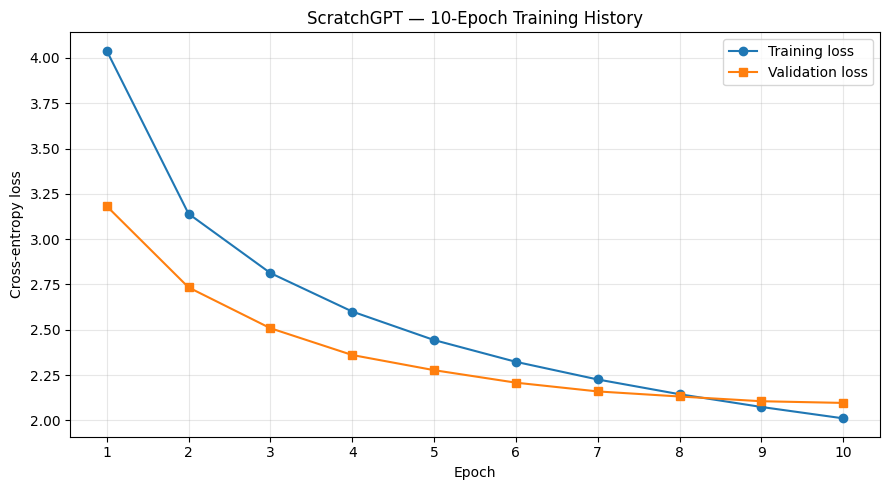

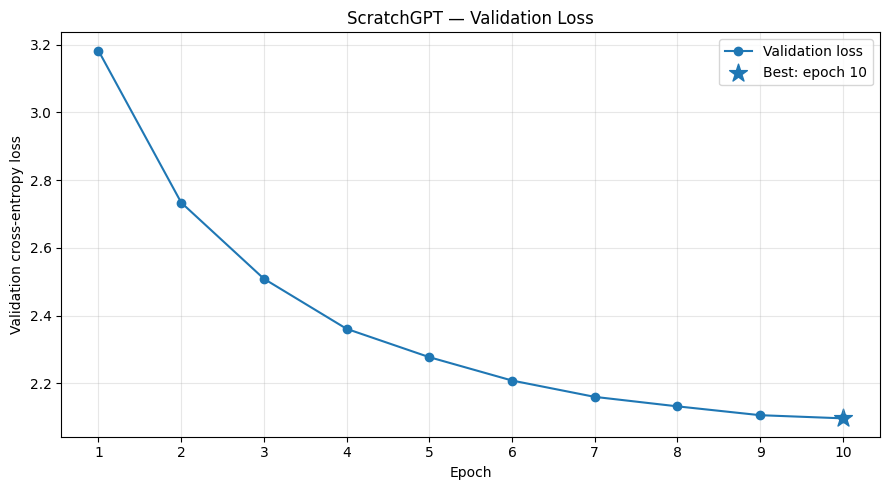


Saved graphs to: /content/drive/MyDrive/ScratchGPT-training/evaluation_10epoch


In [29]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

run_dir = Path("/content/drive/MyDrive/ScratchGPT-training")
history_path = run_dir / "training_history_10epoch.json"
plot_dir = run_dir / "evaluation_10epoch"
plot_dir.mkdir(parents=True, exist_ok=True)

with history_path.open("r", encoding="utf-8") as f:
    history = json.load(f)

assert len(history) == 10, f"Expected 10 epochs, got {len(history)}"
assert all(row["epoch_complete"] for row in history)

epochs = [row["epoch"] for row in history]
train_loss = [row["train_loss"] for row in history]
val_loss = [row["validation_loss"] for row in history]

best_index = min(range(len(val_loss)), key=val_loss.__getitem__)

print("Epochs recorded:", len(history))
print("Best epoch:", epochs[best_index])
print(f"Best validation loss: {val_loss[best_index]:.4f}")

# Plot 1: Training and validation curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker="o", label="Training loss")
plt.plot(epochs, val_loss, marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ScratchGPT — 10-Epoch Training History")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(plot_dir / "loss_curves_10epoch.png", dpi=160)
plt.show()
plt.close()

# Plot 2: Validation loss and best observed epoch
plt.figure(figsize=(9, 5))
plt.plot(epochs, val_loss, marker="o", label="Validation loss")
plt.scatter(
    [epochs[best_index]],
    [val_loss[best_index]],
    marker="*",
    s=180,
    label=f"Best: epoch {epochs[best_index]}",
)
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("ScratchGPT — Validation Loss")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(plot_dir / "validation_loss_10epoch.png", dpi=160)
plt.show()
plt.close()

print("\nSaved graphs to:", plot_dir)

In [30]:
import sys
from pathlib import Path
import torch

project_dir = Path("/content/ScratchGPT").resolve()
src_dir = project_dir / "src"

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens

checkpoint_path = Path(
    "/content/drive/MyDrive/ScratchGPT-training/scratchgpt_10epoch.pt"
)
tokenizer_path = project_dir / "data/processed/tokenizer.json"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["epoch"] == 10

config = GPTConfig(**checkpoint["config"])
model = GPTModel(config)
model.load_state_dict(checkpoint["model_state_dict"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

tokenizer = ByteBPETokenizer.load(tokenizer_path)

prompts = [
    "Once upon a time",
    "A little boy went to the forest",
    "One day, a rabbit found",
    "Lily wanted to help her friend",
]

print("Checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

for index, prompt in enumerate(prompts):
    input_ids = torch.tensor(
        [tokenizer.encode(prompt)],
        dtype=torch.long,
        device=device,
    )

    print("\n" + "=" * 65)
    print(f"PROMPT {index + 1}: {prompt}")
    print("=" * 65)

    with torch.inference_mode():
        greedy = generate_tokens(
            model=model,
            input_ids=input_ids,
            max_new_tokens=100,
            do_sample=False,
        )

    print("\n[GREEDY]")
    print(tokenizer.decode(greedy[0].tolist()))

    seed = 1000 + index
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    with torch.inference_mode():
        sampled = generate_tokens(
            model=model,
            input_ids=input_ids,
            max_new_tokens=100,
            temperature=0.8,
            top_k=40,
            do_sample=True,
        )

    print("\n[SAMPLED]")
    print(tokenizer.decode(sampled[0].tolist()))

Checkpoint epoch: 10
Device: cuda
Parameters: 10,101,760

PROMPT 1: Once upon a time

[GREEDY]
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, shiny stone on the ground. She picked it up and showed it to her mom.

"Look, Mommy! A stone!" Lily said.

"That's so cool! Can I see it?" her mom said.

Lily was so excited to see the stone up close. She picked it up and showed it to her mom. "Look,

[SAMPLED]
Once upon a time, there was a young boy named Jack. Jack was very excited because today he loved to go on adventures. He loved going to the countryside and find interesting things.

As Jack was walking through the woods, he saw a large tree that seemed very tall. He wanted to climb it, so he decided to climb it.

As he climbed the top of the tree, he heard a voice from behind him. It was his mum, â€œWhat is that?â€ 



PROMPT 2: A little boy went to the forest

[GREEDY]
A little boy went to the forest. He saw a big t

In [31]:
import sys
import random
from pathlib import Path

import torch

PROJECT_DIR = Path("/content/ScratchGPT").resolve()
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens

# Existing, completed checkpoints — neither will be overwritten.
BASE_DIR = Path("/content/drive/MyDrive/ScratchGPT-training")
CHECKPOINTS = {
    "3 epochs": BASE_DIR / "scratchgpt.pt",
    "10 epochs": BASE_DIR / "scratchgpt_10epoch.pt",
}

TOKENIZER_PATH = PROJECT_DIR / "data/processed/tokenizer.json"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for name, path in CHECKPOINTS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name} checkpoint: {path}")

if not TOKENIZER_PATH.exists():
    raise FileNotFoundError(f"Missing tokenizer: {TOKENIZER_PATH}")

tokenizer = ByteBPETokenizer.load(str(TOKENIZER_PATH))
config = GPTConfig()

print("Device:", device)
print("Tokenizer vocabulary:", tokenizer.vocab_size)
print("Configured vocabulary:", config.vocab_size)

assert tokenizer.vocab_size == config.vocab_size, (
    "Tokenizer vocabulary and model configuration do not match."
)

# Load both models.
models = {}

for name, path in CHECKPOINTS.items():
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    model = GPTModel(config)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    models[name] = model
    print(f"Loaded {name}: {path.name}")

prompts = [
    "Once upon a time",
    "A little boy went to the forest",
    "One day, a rabbit found",
    "Lily wanted to help her friend",
]

def generate_sample(model, prompt, do_sample, seed=42):
    input_ids = torch.tensor(
        [tokenizer.encode(prompt)],
        dtype=torch.long,
        device=device,
    )

    # Reset the random seed for reproducible sampling.
    if do_sample:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    with torch.inference_mode():
        output_ids = generate_tokens(
            model=model,
            input_ids=input_ids,
            max_new_tokens=100,
            temperature=0.8,
            top_k=40,
            do_sample=do_sample,
        )

    return tokenizer.decode(output_ids[0].tolist())

for prompt_index, prompt in enumerate(prompts):
    print("\n" + "=" * 90)
    print(f"PROMPT {prompt_index + 1}: {prompt}")
    print("=" * 90)

    for mode_name, do_sample in [
        ("GREEDY", False),
        ("SAMPLED", True),
    ]:
        print(f"\n--- {mode_name} ---")

        for model_name, model in models.items():
            result = generate_sample(
                model,
                prompt,
                do_sample=do_sample,
                seed=1000 + prompt_index,
            )

            print(f"\n[{model_name}]")
            print(result)

Device: cuda
Tokenizer vocabulary: 8192
Configured vocabulary: 8192
Loaded 3 epochs: scratchgpt.pt
Loaded 10 epochs: scratchgpt_10epoch.pt

PROMPT 1: Once upon a time

--- GREEDY ---

[3 epochs]
Once upon a time, there was a little girl named Lily. She loved to play outside and play with her friends. One day, Lily's friend Billy came over to play. Timmy was so happy to play with Timmy.

Timmy's friend Billy came over to play. Timmy was so happy to play with Timmy. Timmy's friend Billy said, "Timmy, you can play with me?"

Timmy's friend Billy said, "Yes, but be careful. We can play together."

Timmy's

[10 epochs]
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, shiny stone on the ground. She picked it up and showed it to her mom.

"Look, Mommy! A stone!" Lily said.

"That's so cool! Can I see it?" her mom said.

Lily was so excited to see the stone up close. She picked it up and showed it to her mom. "Look,

--- S

In [32]:
test_strings = [
    '"What is that?"',
    "“What is that?”",
    "‘Hello,’ said Lily.",
    "It's a beautiful day.",
    "The boy ran — and laughed.",
    "Café and naïve",
]

print("TOKENIZER ROUND-TRIP DIAGNOSTIC")
print("=" * 70)

for original in test_strings:
    token_ids = tokenizer.encode(original)
    decoded = tokenizer.decode(token_ids)

    passed = decoded == original

    print(f"\nOriginal: {original!r}")
    print(f"Decoded:  {decoded!r}")
    print(f"Exact match: {'PASS' if passed else 'FAIL'}")

TOKENIZER ROUND-TRIP DIAGNOSTIC

Original: '"What is that?"'
Decoded:  '"What is that?"'
Exact match: PASS

Original: '“What is that?”'
Decoded:  '“What is that?”'
Exact match: PASS

Original: '‘Hello,’ said Lily.'
Decoded:  '‘Hello,’ said Lily.'
Exact match: PASS

Original: "It's a beautiful day."
Decoded:  "It's a beautiful day."
Exact match: PASS

Original: 'The boy ran — and laughed.'
Decoded:  'The boy ran — and laughed.'
Exact match: PASS

Original: 'Café and naïve'
Decoded:  'Café and naïve'
Exact match: PASS


In [33]:
from pathlib import Path

data_files = {
    "TRAIN": Path(
        "/content/ScratchGPT/data/raw/train/tinystories_train.txt"
    ),
    "VALIDATION": Path(
        "/content/ScratchGPT/data/raw/validation/tinystories_validation.txt"
    ),
}

suspect_patterns = [
    "â€œ",
    "â€",
    "â€™",
    "Ã©",
    "Ã¨",
    "ï¿½",
    "\ufffd",
]

for split_name, path in data_files.items():
    print("\n" + "=" * 75)
    print(f"{split_name}: {path}")
    print("=" * 75)

    text = path.read_text(encoding="utf-8", errors="strict")

    print("UTF-8 decoding: PASS")
    print("Characters:", len(text))
    print("Replacement character count:", text.count("\ufffd"))

    for pattern in suspect_patterns:
        count = text.count(pattern)
        if count:
            print(f"\nFound {pattern!r}: {count} occurrence(s)")

            shown = 0
            start = 0

            while shown < 3:
                index = text.find(pattern, start)
                if index == -1:
                    break

                left = max(0, index - 100)
                right = min(len(text), index + 150)
                print("Context:", repr(text[left:right]))

                start = index + len(pattern)
                shown += 1

    if not any(pattern in text for pattern in suspect_patterns):
        print("No listed corruption patterns found.")


TRAIN: /content/ScratchGPT/data/raw/train/tinystories_train.txt
UTF-8 decoding: PASS
Characters: 8694761
Replacement character count: 0

Found 'â€œ': 1645 occurrence(s)
Context: ' to take a closer look. She walked up to the arrow and suddenly a voice shouted at her from behind, â€œBe careful not to touch it!â€ Annie jumped back in fright and saw an old man.  \n \nThe old man said, â€œMy name is Wilbur and I was just minding my '
Context: 'Be careful not to touch it!â€ Annie jumped back in fright and saw an old man.  \n \nThe old man said, â€œMy name is Wilbur and I was just minding my own business when I saw you walking towards the arrow. I was worried that you may get injured, so I sho'
Context: 'g towards the arrow. I was worried that you may get injured, so I shouted.â€\nAnnie smiled and said, â€œThank you Wilbur, I will mind your advice."\nWilbur smiled back and replied, â€œThatâ€™s very wise young lady. Now why donâ€™t we just run away and '

Found 'â€': 4534 occurrence(s)
Contex

In [34]:
from pathlib import Path

data_files = {
    "TRAIN": Path(
        "/content/ScratchGPT/data/raw/train/tinystories_train.txt"
    ),
    "VALIDATION": Path(
        "/content/ScratchGPT/data/raw/validation/tinystories_validation.txt"
    ),
}

# Repair only the corruption patterns we've observed.
# Replace the opening quote first because it contains the "â€" prefix.
replacements = [
    ("â€œ", "“"),
    ("â€™", "’"),
    ("â€", "”"),
    ("cafÃ©", "café"),
    ("MamÃ¡", "Mamá"),
]

repaired_texts = {}

for split_name, path in data_files.items():
    original = path.read_text(encoding="utf-8", errors="strict")
    repaired = original
    print("\n" + "=" * 70)
    print(split_name)

    for broken, corrected in replacements:
        count = repaired.count(broken)
        if count:
            print(f"{broken!r} -> {corrected!r}: {count} replacement(s)")
            repaired = repaired.replace(broken, corrected)

    repaired_texts[split_name] = repaired

    print("Original characters:", len(original))
    print("Repaired characters:", len(repaired))
    print("Original unchanged on disk: YES (dry-run only)")

    for marker in ["â€œ", "â€™", "â€", "cafÃ©", "MamÃ¡"]:
        remaining = repaired.count(marker)
        if remaining:
            print(f"Still present {marker!r}: {remaining}")

    # Display an example before and after repair.
    marker = "Be careful not to touch it!"
    position = original.find(marker)

    if position >= 0:
        print("\nBEFORE:")
        print(repr(original[max(0, position - 35):position + 100]))

        repaired_position = repaired.find(marker)
        print("\nAFTER:")
        print(
            repr(
                repaired[
                    max(0, repaired_position - 35):
                    repaired_position + 100
                ]
            )
        )

print("\nDry-run complete. No files were written.")


TRAIN
'â€œ' -> '“': 1645 replacement(s)
'â€™' -> '’': 1149 replacement(s)
'â€' -> '”': 1740 replacement(s)
'cafÃ©' -> 'café': 3 replacement(s)
'MamÃ¡' -> 'Mamá': 1 replacement(s)
Original characters: 8694761
Repaired characters: 8687429
Original unchanged on disk: YES (dry-run only)

BEFORE:
'ice shouted at her from behind, â€œBe careful not to touch it!â€ Annie jumped back in fright and saw an old man.  \n \nThe old man said, '

AFTER:
'voice shouted at her from behind, “Be careful not to touch it!” Annie jumped back in fright and saw an old man.  \n \nThe old man said, “'

VALIDATION
'â€œ' -> '“': 15 replacement(s)
'â€™' -> '’': 8 replacement(s)
'â€' -> '”': 16 replacement(s)
Original characters: 406081
Repaired characters: 406019
Original unchanged on disk: YES (dry-run only)

Dry-run complete. No files were written.


In [35]:
from pathlib import Path
import hashlib

PROJECT_DIR = Path("/content/ScratchGPT")

source_files = {
    "train": PROJECT_DIR / "data/raw/train/tinystories_train.txt",
    "validation": PROJECT_DIR / "data/raw/validation/tinystories_validation.txt",
}

output_files = {
    "train": PROJECT_DIR / "data/cleaned/train/tinystories_train.txt",
    "validation": PROJECT_DIR / "data/cleaned/validation/tinystories_validation.txt",
}

# Apply specific repairs observed in the source files.
# Longer patterns are handled before shorter overlapping patterns.
replacements = [
    ("â€œ", "“"),
    ("â€™", "’"),
    ("â€", "”"),
    ("cafÃ©", "café"),
    ("MamÃ¡", "Mamá"),
]

# Known corruption markers to check after repair.
markers_to_check = [
    "â€œ",
    "â€™",
    "â€",
    "cafÃ©",
    "MamÃ¡",
    "ï¿½",
    "\ufffd",
]

original_hashes = {}
cleaned_texts = {}

for split in ("train", "validation"):
    source_path = source_files[split]
    output_path = output_files[split]

    original = source_path.read_text(encoding="utf-8", errors="strict")
    original_hashes[split] = hashlib.sha256(
        source_path.read_bytes()
    ).hexdigest()

    cleaned = original
    print(f"\n{'=' * 65}\n{split.upper()}\n{'=' * 65}")

    for broken, corrected in replacements:
        count = cleaned.count(broken)
        if count:
            cleaned = cleaned.replace(broken, corrected)
            print(f"{broken!r} -> {corrected!r}: {count}")

    remaining = {
        marker: cleaned.count(marker)
        for marker in markers_to_check
        if cleaned.count(marker) > 0
    }

    if remaining:
        print("\nWARNING: known markers remain:")
        for marker, count in remaining.items():
            print(f"  {marker!r}: {count}")
    else:
        print("Known corruption-marker check: PASS")

    output_path.parent.mkdir(parents=True, exist_ok=True)
    output_path.write_text(cleaned, encoding="utf-8", newline="")

    # Read the saved file back and verify it.
    saved = output_path.read_text(encoding="utf-8", errors="strict")
    assert saved == cleaned, f"Saved text differs: {output_path}"

    cleaned_texts[split] = cleaned

    print("Original characters:", len(original))
    print("Cleaned characters:", len(cleaned))
    print("Saved copy:", output_path)
    print("Saved-copy verification: PASS")

# Verify that the original files were not modified.
for split, path in source_files.items():
    current_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    assert current_hash == original_hashes[split], (
        f"Original {split} file changed unexpectedly!"
    )

print("\nOriginal source files unchanged: PASS")
print("Cleaned files created and verified.")


TRAIN
'â€œ' -> '“': 1645
'â€™' -> '’': 1149
'â€' -> '”': 1740
'cafÃ©' -> 'café': 3
'MamÃ¡' -> 'Mamá': 1
Known corruption-marker check: PASS
Original characters: 8694761
Cleaned characters: 8687429
Saved copy: /content/ScratchGPT/data/cleaned/train/tinystories_train.txt
Saved-copy verification: PASS

VALIDATION
'â€œ' -> '“': 15
'â€™' -> '’': 8
'â€' -> '”': 16
Known corruption-marker check: PASS
Original characters: 406081
Cleaned characters: 406019
Saved copy: /content/ScratchGPT/data/cleaned/validation/tinystories_validation.txt
Saved-copy verification: PASS

Original source files unchanged: PASS
Cleaned files created and verified.


In [36]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train_tokenizer.py \
    --input-dir data/cleaned/train \
    --output data/processed/tokenizer_cleaned.json \
    --vocab-size 8192 \
    --min-frequency 2

/content/ScratchGPT
ScratchGPT tokenizer training
Input directory: /content/ScratchGPT/data/cleaned/train
Text files loaded: 1
Characters loaded: 8,687,429
UTF-8 bytes loaded: 8,696,714
Target vocabulary size: 8,192
Minimum pair frequency: 2

Training complete
--------------------------------
Final vocabulary size: 8,192
Learned merges: 7,936
Sample characters: 500
Sample token IDs: 124
Sample characters per token: 4.03
Saved tokenizer: /content/ScratchGPT/data/processed/tokenizer_cleaned.json
Elapsed time: 67.95 seconds


In [37]:
import json
from pathlib import Path
from scratchgpt.tokenizer import ByteBPETokenizer

new_tokenizer_path = Path(
    "/content/ScratchGPT/data/processed/tokenizer_cleaned.json"
)
old_tokenizer_path = Path(
    "/content/ScratchGPT/data/processed/tokenizer.json"
)

assert new_tokenizer_path.exists(), "New tokenizer file was not created."
assert old_tokenizer_path.exists(), "Original tokenizer is missing."

new_tokenizer = ByteBPETokenizer.load(str(new_tokenizer_path))
old_tokenizer = ByteBPETokenizer.load(str(old_tokenizer_path))

print("Original tokenizer vocabulary:", old_tokenizer.vocab_size)
print("Cleaned tokenizer vocabulary:", new_tokenizer.vocab_size)

assert new_tokenizer.vocab_size == 8192, (
    f"Unexpected vocabulary size: {new_tokenizer.vocab_size}"
)

# Verify that the new tokenizer preserves cleaned Unicode text.
examples = [
    "“Be careful not to touch it!”",
    "That’s very wise.",
    "Let’s go to the café.",
    "Once upon a time, there was a little girl named Lily.",
]

for text in examples:
    decoded = new_tokenizer.decode(new_tokenizer.encode(text))
    print(f"\nOriginal: {text!r}")
    print(f"Decoded:  {decoded!r}")
    assert decoded == text, f"Round-trip failed for: {text!r}"

# Confirm that the original tokenizer file remains untouched.
with open(old_tokenizer_path, "r", encoding="utf-8") as f:
    old_data = json.load(f)

print("\nOriginal tokenizer still exists: PASS")
print("New tokenizer round-trip checks: PASS")

Original tokenizer vocabulary: 8192
Cleaned tokenizer vocabulary: 8192

Original: '“Be careful not to touch it!”'
Decoded:  '“Be careful not to touch it!”'

Original: 'That’s very wise.'
Decoded:  'That’s very wise.'

Original: 'Let’s go to the café.'
Decoded:  'Let’s go to the café.'

Original: 'Once upon a time, there was a little girl named Lily.'
Decoded:  'Once upon a time, there was a little girl named Lily.'

Original tokenizer still exists: PASS
New tokenizer round-trip checks: PASS


In [38]:
import sys
from pathlib import Path
import math

sys.path.insert(0, "/content/ScratchGPT/src")

from scratchgpt.tokenizer import ByteBPETokenizer

PROJECT_DIR = Path("/content/ScratchGPT")
TOKENIZER_PATH = PROJECT_DIR / "data/processed/tokenizer_cleaned.json"

DATA_FILES = {
    "TRAIN": PROJECT_DIR / "data/cleaned/train/tinystories_train.txt",
    "VALIDATION": PROJECT_DIR / "data/cleaned/validation/tinystories_validation.txt",
}

tokenizer = ByteBPETokenizer.load(str(TOKENIZER_PATH))

SEQUENCE_LENGTH = 256
STRIDE = 256
BATCH_SIZE = 8

print("CLEANED DATASET TOKENIZATION AUDIT")
print("=" * 65)
print("Tokenizer vocabulary:", tokenizer.vocab_size)
print("Sequence length:", SEQUENCE_LENGTH)
print("Stride:", STRIDE)
print("Batch size:", BATCH_SIZE)

token_counts = {}

for split_name, path in DATA_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {split_name} file: {path}")

    text = path.read_text(encoding="utf-8", errors="strict")
    token_ids = tokenizer.encode(text)

    # A next-token example needs 256 input tokens plus the
    # following token as its target.
    if len(token_ids) < SEQUENCE_LENGTH + 1:
        raise ValueError(f"{split_name} contains too few tokens.")

    num_examples = (
        (len(token_ids) - SEQUENCE_LENGTH - 1) // STRIDE
    ) + 1

    num_batches = math.ceil(num_examples / BATCH_SIZE)

    token_counts[split_name] = len(token_ids)

    print(f"\n{split_name}")
    print("-" * 40)
    print("Characters:", len(text))
    print("UTF-8 bytes:", len(text.encode("utf-8")))
    print("Encoded tokens:", f"{len(token_ids):,}")
    print("Next-token examples:", f"{num_examples:,}")
    print("Expected batches per epoch:", f"{num_batches:,}")
    print("First 20 token IDs:", token_ids[:20])

print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("Training tokens:", f"{token_counts['TRAIN']:,}")
print("Validation tokens:", f"{token_counts['VALIDATION']:,}")
print("Validation data used to train tokenizer: NO")

CLEANED DATASET TOKENIZATION AUDIT
Tokenizer vocabulary: 8192
Sequence length: 256
Stride: 256
Batch size: 8

TRAIN
----------------------------------------
Characters: 8687429
UTF-8 bytes: 8696714
Encoded tokens: 2,127,557
Next-token examples: 8,310
Expected batches per epoch: 1,039
First 20 token IDs: [414, 352, 44, 258, 386, 438, 489, 369, 585, 258, 3797, 313, 309, 737, 46, 312, 688, 304, 279, 2983]

VALIDATION
----------------------------------------
Characters: 406019
UTF-8 bytes: 406099
Encoded tokens: 99,394
Next-token examples: 388
Expected batches per epoch: 49
First 20 token IDs: [3549, 46, 1192, 411, 262, 982, 567, 264, 321, 44, 324, 1324, 44, 2351, 44, 641, 567, 424, 344, 1134]

AUDIT COMPLETE
Training tokens: 2,127,557
Validation tokens: 99,394
Validation data used to train tokenizer: NO


In [39]:
from pathlib import Path

script_path = Path("/content/ScratchGPT/scripts/train.py")
source = script_path.read_text(encoding="utf-8")
lines = source.splitlines()

keywords = [
    "tokenizer",
    "train_path",
    "validation_path",
    "train_dir",
    "validation_dir",
    "data/raw",
    "data/processed",
    "ArgumentParser",
    "add_argument",
    "checkpoint",
    "history",
]

print("TRAINING SCRIPT CONFIGURATION AUDIT")
print("=" * 75)

for index, line in enumerate(lines):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        start = max(0, index - 1)
        end = min(len(lines), index + 2)

        print(f"\nLines {start + 1}-{end}:")
        for line_number in range(start, end):
            print(f"{line_number + 1:4}: {lines[line_number]}")

TRAINING SCRIPT CONFIGURATION AUDIT

Lines 12-14:
  12: 
  13: from scratchgpt.checkpoint import load_checkpoint, save_checkpoint
  14: from scratchgpt.config import GPTConfig

Lines 17-19:
  17: from scratchgpt.model import GPTModel
  18: from scratchgpt.tokenizer import ByteBPETokenizer
  19: from scratchgpt.training import evaluate_loss, train_one_epoch

Lines 23-25:
  23:     """Parse command-line training options."""
  24:     parser = argparse.ArgumentParser(description="Train ScratchGPT on TinyStories.")
  25:     parser.add_argument("--epochs", type=int, default=3)

Lines 24-26:
  24:     parser = argparse.ArgumentParser(description="Train ScratchGPT on TinyStories.")
  25:     parser.add_argument("--epochs", type=int, default=3)
  26:     parser.add_argument("--batch-size", type=int, default=8)

Lines 25-27:
  25:     parser.add_argument("--epochs", type=int, default=3)
  26:     parser.add_argument("--batch-size", type=int, default=8)
  27:     parser.add_argument("--sequence

In [40]:
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

output_dir = Path("/content/drive/MyDrive/ScratchGPT-training")
output_dir.mkdir(parents=True, exist_ok=True)

required_files = [
    Path("/content/ScratchGPT/data/processed/tokenizer_cleaned.json"),
    Path("/content/ScratchGPT/data/cleaned/train/tinystories_train.txt"),
    Path("/content/ScratchGPT/data/cleaned/validation/tinystories_validation.txt"),
]

for path in required_files:
    assert path.is_file(), f"Missing required file: {path}"
    print(f"Verified: {path}")

print("\nDrive output directory:", output_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified: /content/ScratchGPT/data/processed/tokenizer_cleaned.json
Verified: /content/ScratchGPT/data/cleaned/train/tinystories_train.txt
Verified: /content/ScratchGPT/data/cleaned/validation/tinystories_validation.txt

Drive output directory: /content/drive/MyDrive/ScratchGPT-training


In [41]:
%cd /content/ScratchGPT

!PYTHONPATH=/content/ScratchGPT/src python scripts/train.py \
    --epochs 10 \
    --batch-size 8 \
    --sequence-length 256 \
    --stride 256 \
    --learning-rate 0.0003 \
    --seed 42 \
    --device cuda \
    --tokenizer data/processed/tokenizer_cleaned.json \
    --train-file data/cleaned/train/tinystories_train.txt \
    --validation-file data/cleaned/validation/tinystories_validation.txt \
    --checkpoint /content/drive/MyDrive/ScratchGPT-training/scratchgpt_cleaned_10epoch.pt \
    --history /content/drive/MyDrive/ScratchGPT-training/training_history_cleaned_10epoch.json

/content/ScratchGPT
Loading and encoding training data...
Loading and encoding validation data...

ScratchGPT training
Device: cuda
Parameters: 10,101,760
Vocabulary: 8,192
Training tokens: 2,127,557
Validation tokens: 99,394
Training examples: 8,310
Validation examples: 388
Training batches per full epoch: 1,039
Validation batches: 49
Batch size: 8
Sequence length: 256
Stride: 256
Target completed epochs: 10
Already completed epochs: 0
Learning rate: 0.0003
Resume enabled: False

Epoch 1/10 | status=complete | train_batches=1039/1039 | validation_batches=49/49 | train_loss=4.0441 | validation_loss=3.1917 | time=63.5s
Checkpoint saved: /content/drive/MyDrive/ScratchGPT-training/scratchgpt_cleaned_10epoch.pt
History saved: /content/drive/MyDrive/ScratchGPT-training/training_history_cleaned_10epoch.json
Epoch 2/10 | status=complete | train_batches=1039/1039 | validation_batches=49/49 | train_loss=3.1567 | validation_loss=2.7536 | time=66.5s
Checkpoint saved: /content/drive/MyDrive/Scratc

In [42]:
import json
from pathlib import Path

output_dir = Path("/content/drive/MyDrive/ScratchGPT-training")

checkpoint_path = output_dir / "scratchgpt_cleaned_10epoch.pt"
history_path = output_dir / "training_history_cleaned_10epoch.json"

assert checkpoint_path.is_file(), "Cleaned-model checkpoint is missing."
assert history_path.is_file(), "Cleaned-model history is missing."

history = json.loads(history_path.read_text(encoding="utf-8"))

print("Checkpoint size:", f"{checkpoint_path.stat().st_size:,}", "bytes")
print("Recorded epochs:", len(history))

print("\nEPOCH | TRAIN LOSS | VALIDATION LOSS | COMPLETE")
print("-" * 55)

for record in history:
    print(
        f"{record['epoch']:5d} | "
        f"{record['train_loss']:10.4f} | "
        f"{record['validation_loss']:15.4f} | "
        f"{record['epoch_complete']}"
    )

assert len(history) == 10, "Expected 10 epoch records."
assert all(record["epoch_complete"] for record in history), (
    "At least one epoch is incomplete."
)

print("\nTraining-history verification: PASS")

Checkpoint size: 121,335,444 bytes
Recorded epochs: 10

EPOCH | TRAIN LOSS | VALIDATION LOSS | COMPLETE
-------------------------------------------------------
    1 |     4.0441 |          3.1917 | True
    2 |     3.1567 |          2.7536 | True
    3 |     2.8279 |          2.5195 | True
    4 |     2.6171 |          2.3783 | True
    5 |     2.4617 |          2.2810 | True
    6 |     2.3401 |          2.2186 | True
    7 |     2.2415 |          2.1703 | True
    8 |     2.1594 |          2.1390 | True
    9 |     2.0882 |          2.1176 | True
   10 |     2.0257 |          2.1014 | True

Training-history verification: PASS


In [43]:
import sys
from pathlib import Path

import torch

project_dir = Path("/content/ScratchGPT").resolve()
sys.path.insert(0, str(project_dir / "src"))

from scratchgpt.model import GPTConfig, GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens

output_dir = Path("/content/drive/MyDrive/ScratchGPT-training")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

experiments = {
    "ORIGINAL DATA": {
        "checkpoint": output_dir / "scratchgpt_10epoch.pt",
        "tokenizer": project_dir / "data/processed/tokenizer.json",
    },
    "CLEANED DATA": {
        "checkpoint": output_dir / "scratchgpt_cleaned_10epoch.pt",
        "tokenizer": project_dir / "data/processed/tokenizer_cleaned.json",
    },
}

prompts = [
    "Once upon a time",
    "Lily went into the forest",
    "One sunny morning, a little rabbit",
    "Tom wanted to help his friend",
]

loaded_models = {}

for name, paths in experiments.items():
    assert paths["checkpoint"].is_file(), (
        f"Checkpoint missing: {paths['checkpoint']}"
    )
    assert paths["tokenizer"].is_file(), (
        f"Tokenizer missing: {paths['tokenizer']}"
    )

    tokenizer = ByteBPETokenizer.load(str(paths["tokenizer"]))

    config = GPTConfig(
        vocab_size=tokenizer.vocab_size,
        context_length=256,
    )

    model = GPTModel(config).to(device)

    checkpoint = torch.load(
        paths["checkpoint"],
        map_location=device,
        weights_only=True,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    loaded_models[name] = (model, tokenizer)

    print(
        f"Loaded {name}: "
        f"{sum(p.numel() for p in model.parameters()):,} parameters"
    )

print("\n" + "=" * 80)
print("QUALITATIVE GENERATION COMPARISON")
print("=" * 80)

for prompt in prompts:
    print(f"\n\nPROMPT: {prompt}")
    print("-" * 80)

    for name, (model, tokenizer) in loaded_models.items():
        print(f"\n### {name}")

        for mode in ("greedy", "sampled"):
            # Reset the random seed for reproducible sampled generations.
            torch.manual_seed(123)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(123)

            input_ids = torch.tensor(
                [tokenizer.encode(prompt)],
                dtype=torch.long,
                device=device,
            )

            with torch.inference_mode():
                generated = generate_tokens(
                    model,
                    input_ids,
                    max_new_tokens=100,
                    temperature=0.8,
                    top_k=40,
                    do_sample=(mode == "sampled"),
                )

            generated_ids = generated[0].tolist()
            text = tokenizer.decode(generated_ids)

            print(f"\n[{mode.upper()}]")
            print(text)

print("\n\nGeneration comparison completed.")

Loaded ORIGINAL DATA: 10,101,760 parameters
Loaded CLEANED DATA: 10,101,760 parameters

QUALITATIVE GENERATION COMPARISON


PROMPT: Once upon a time
--------------------------------------------------------------------------------

### ORIGINAL DATA

[GREEDY]
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, shiny stone on the ground. She picked it up and showed it to her mom.

"Look, Mommy! A stone!" Lily said.

"That's so cool! Can I see it?" her mom said.

Lily was so excited to see the stone up close. She picked it up and showed it to her mom. "Look,

[SAMPLED]
Once upon a time, there was a little boy named Timmy. Timmy loved to play with his toys and run high in the sky. One day, Timmy's friend Billy came over to play. Billy wanted to play too, so Timmy asked Billy if he could join them. Billy said yes and they went to the big box.

As they were playing, Timmy accidentally knocked over a rock and it broke! Timmy

In [44]:
from pathlib import Path

train_path = Path(
    "/content/ScratchGPT/data/cleaned/train/tinystories_train.txt"
)
validation_path = Path(
    "/content/ScratchGPT/data/cleaned/validation/tinystories_validation.txt"
)

markers = [
    "<|endoftext|>",
    "<|eos|>",
    "<EOS>",
    "\n\n",
]

for label, path in [
    ("TRAIN", train_path),
    ("VALIDATION", validation_path),
]:
    text = path.read_text(encoding="utf-8")

    print(f"\n{'=' * 60}")
    print(label)
    print(f"{'=' * 60}")
    print("Characters:", len(text))
    print("Lines:", len(text.splitlines()))
    print("Non-empty lines:", sum(bool(line.strip()) for line in text.splitlines()))

    for marker in markers:
        print(f"Occurrences of {marker!r}: {text.count(marker):,}")

    print("\nFirst 1,200 characters:")
    print(repr(text[:1200]))

    print("\nLast 500 characters:")
    print(repr(text[-500:]))


TRAIN
Characters: 8687429
Lines: 104453
Non-empty lines: 52631
Occurrences of '<|endoftext|>': 0
Occurrences of '<|eos|>': 0
Occurrences of '<EOS>': 0
Occurrences of '\n\n': 51,749

First 1,200 characters:
'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.\n\nLily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."\n\nTogether, they shared the needle and sewed the button on Lily\'s shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.\n\nOnce upon a time, there was a little car named Beep. Beep loved to go fast and pla

In [45]:
from pathlib import Path

project = Path("/content/ScratchGPT")

files_to_audit = [
    project / "src/scratchgpt/tokenizer.py",
    project / "src/scratchgpt/dataset.py",
    project / "src/scratchgpt/generation.py",
    project / "scripts/train.py",
]

keywords = (
    "def encode",
    "def decode",
    "def train",
    "def __init__",
    "def __getitem__",
    "def generate_tokens",
    "special",
    "endoftext",
    "eos",
    "split(",
    "read_text",
    "read_bytes",
    "tokenizer.encode",
    "tokenizer.decode",
)

for path in files_to_audit:
    print("\n" + "=" * 90)
    print(f"FILE: {path.relative_to(project)}")
    print("=" * 90)

    if not path.is_file():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()
    matches = set()

    for index, line in enumerate(lines):
        if any(keyword in line.lower() for keyword in keywords):
            start = max(0, index - 2)
            end = min(len(lines), index + 4)
            matches.update(range(start, end))

    if not matches:
        print("No matching lines found.")
        continue

    previous = -2
    for index in sorted(matches):
        if index > previous + 1:
            print("...")
        print(f"{index + 1:4}: {lines[index]}")
        previous = index


FILE: src/scratchgpt/tokenizer.py
...
  24:     """Learn byte-pair merges from text and encode text into token IDs."""
  25: 
  26:     def __init__(self) -> None:
  27:         self.token_bytes: dict[int, bytes] = {}
  28:         self.byte_to_id: dict[bytes, int] = {}
  29:         self.merges: list[tuple[int, int, int]] = []
...
 103:         return pair_counts, pair_to_sequences
 104: 
 105:     def train(
 106:         self,
 107:         texts: Sequence[str],
 108:         vocab_size: int = 512,
...
 191:                     pair_to_sequences.setdefault(pair, set()).add(sequence_id)
 192: 
 193:     def encode(self, text: str) -> list[int]:
 194:         """Encode text using learned BPE merge priorities."""
 195:         if not isinstance(text, str):
 196:             raise TypeError("text must be a string")
...
 234:         return token_ids
 235: 
 236:     def decode(self, token_ids: Sequence[int]) -> str:
 237:         """Decode token IDs into UTF-8 text."""
 238:         if

In [47]:
from pathlib import Path

project = Path("/content/ScratchGPT")

files_and_ranges = {
    "src/scratchgpt/tokenizer.py": (1, 330),
    "src/scratchgpt/dataset.py": (1, 100),
    "src/scratchgpt/generation.py": (1, 180),
}

for relative_path, (start, end) in files_and_ranges.items():
    path = project / relative_path
    lines = path.read_text(encoding="utf-8").splitlines()

    print("\n" + "=" * 80)
    print(f"FILE: {relative_path} | {len(lines)} total lines")
    print("=" * 80)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")


FILE: src/scratchgpt/tokenizer.py | 334 total lines
   1: """Byte-level BPE tokenizer for ScratchGPT."""
   2: 
   3: import json
   4: from collections import Counter
   5: from collections.abc import Sequence
   6: from pathlib import Path
   7: from typing import Any
   8: 
   9: import regex
  10: 
  11: GPT2_PATTERN = (
  12:     r"""'s|'t|'re|'ve|'m|'ll|'d"""
  13:     r"""| ?\p{L}+"""
  14:     r"""| ?\p{N}+"""
  15:     r"""| ?[^\s\p{L}\p{N}]+"""
  16:     r"""|\s+(?!\S)"""
  17:     r"""|\s+"""
  18: )
  19: 
  20: TOKENIZER_FORMAT = "scratchgpt-byte-bpe-v1"
  21: 
  22: 
  23: class ByteBPETokenizer:
  24:     """Learn byte-pair merges from text and encode text into token IDs."""
  25: 
  26:     def __init__(self) -> None:
  27:         self.token_bytes: dict[int, bytes] = {}
  28:         self.byte_to_id: dict[bytes, int] = {}
  29:         self.merges: list[tuple[int, int, int]] = []
  30:         self._reset_vocabulary()
  31: 
  32:     def _reset_vocabulary(self) -> No

In [48]:
from pathlib import Path

path = Path("/content/ScratchGPT/src/scratchgpt/tokenizer.py")

print("File exists:", path.exists())

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()
    print("Total lines:", len(lines))
    print("\n".join(
        f"{i + 1:4}: {line}"
        for i, line in enumerate(lines[:100])
    ))

File exists: True
Total lines: 334
   1: """Byte-level BPE tokenizer for ScratchGPT."""
   2: 
   3: import json
   4: from collections import Counter
   5: from collections.abc import Sequence
   6: from pathlib import Path
   7: from typing import Any
   8: 
   9: import regex
  10: 
  11: GPT2_PATTERN = (
  12:     r"""'s|'t|'re|'ve|'m|'ll|'d"""
  13:     r"""| ?\p{L}+"""
  14:     r"""| ?\p{N}+"""
  15:     r"""| ?[^\s\p{L}\p{N}]+"""
  16:     r"""|\s+(?!\S)"""
  17:     r"""|\s+"""
  18: )
  19: 
  20: TOKENIZER_FORMAT = "scratchgpt-byte-bpe-v1"
  21: 
  22: 
  23: class ByteBPETokenizer:
  24:     """Learn byte-pair merges from text and encode text into token IDs."""
  25: 
  26:     def __init__(self) -> None:
  27:         self.token_bytes: dict[int, bytes] = {}
  28:         self.byte_to_id: dict[bytes, int] = {}
  29:         self.merges: list[tuple[int, int, int]] = []
  30:         self._reset_vocabulary()
  31: 
  32:     def _reset_vocabulary(self) -> None:
  33:         

In [49]:
from pathlib import Path

project = Path("/content/ScratchGPT")

sections = {
    "src/scratchgpt/tokenizer.py": (101, 334),
    "src/scratchgpt/dataset.py": (1, 100),
    "src/scratchgpt/generation.py": (1, 180),
}

for filename, (start, end) in sections.items():
    path = project / filename
    lines = path.read_text(encoding="utf-8").splitlines()

    print(f"\n{'=' * 80}")
    print(f"{filename} — lines {start}–{min(end, len(lines))}")
    print("=" * 80)

    for index in range(start - 1, min(end, len(lines))):
        print(f"{index + 1:4}: {lines[index]}")


src/scratchgpt/tokenizer.py — lines 101–334
 101:                 pair_to_sequences.setdefault(pair, set()).add(sequence_id)
 102: 
 103:         return pair_counts, pair_to_sequences
 104: 
 105:     def train(
 106:         self,
 107:         texts: Sequence[str],
 108:         vocab_size: int = 512,
 109:         min_frequency: int = 2,
 110:     ) -> None:
 111:         """Learn BPE merges using incrementally maintained pair statistics."""
 112:         if isinstance(texts, (str, bytes)):
 113:             raise TypeError("texts must be a sequence of strings, not one string")
 114: 
 115:         if not isinstance(texts, Sequence):
 116:             raise TypeError("texts must be a sequence of strings")
 117: 
 118:         if any(not isinstance(text, str) for text in texts):
 119:             raise TypeError("every training item must be a string")
 120: 
 121:         if type(vocab_size) is not int or vocab_size < 256:
 122:             raise ValueError("vocab_size must be an in

In [50]:
from pathlib import Path

project = Path("/content/ScratchGPT")

sections = {
    "tests/test_tokenizer.py": (1, 400),
    "tests/test_generation.py": (1, 300),
    "scripts/train.py": (1, 180),
}

for filename, (start, end) in sections.items():
    path = project / filename
    print(f"\n{'=' * 80}\n{filename}\n{'=' * 80}")

    if not path.is_file():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()

    for index in range(start - 1, min(end, len(lines))):
        print(f"{index + 1:4}: {lines[index]}")


tests/test_tokenizer.py
FILE NOT FOUND

tests/test_generation.py
FILE NOT FOUND

scripts/train.py
   1: """Train ScratchGPT from scratch on tokenized TinyStories data."""
   2: 
   3: import argparse
   4: import json
   5: import math
   6: import random
   7: import time
   8: from itertools import islice
   9: from pathlib import Path
  10: 
  11: import torch
  12: 
  13: from scratchgpt.checkpoint import load_checkpoint, save_checkpoint
  14: from scratchgpt.config import GPTConfig
  15: from scratchgpt.dataloaders import create_dataloaders
  16: from scratchgpt.dataset import NextTokenDataset, load_token_ids
  17: from scratchgpt.model import GPTModel
  18: from scratchgpt.tokenizer import ByteBPETokenizer
  19: from scratchgpt.training import evaluate_loss, train_one_epoch
  20: 
  21: 
  22: def parse_args() -> argparse.Namespace:
  23:     """Parse command-line training options."""
  24:     parser = argparse.ArgumentParser(description="Train ScratchGPT on TinyStories.")
  25

In [51]:
from pathlib import Path

project = Path("/content/ScratchGPT")

print("PROJECT FILES")
print("=" * 80)

for path in sorted(project.rglob("*")):
    if not path.is_file():
        continue

    relative = path.relative_to(project)

    # Skip generated data, environments, and caches.
    if any(
        part in {"data", ".git", ".venv", "__pycache__"}
        for part in relative.parts
    ):
        continue

    print(relative)

PROJECT FILES
pyproject.toml
scripts/__init__.py
scripts/benchmark_tokenizer.py
scripts/compare_tokenizer.py
scripts/diagnose_loss.py
scripts/download_tinystories.py
scripts/estimate_training_workload.py
scripts/stream_tinystories.py
scripts/train.py
scripts/train_tokenizer.py
src/scratchgpt/__init__.py
src/scratchgpt/attention.py
src/scratchgpt/checkpoint.py
src/scratchgpt/config.py
src/scratchgpt/dataloaders.py
src/scratchgpt/dataset.py
src/scratchgpt/embeddings.py
src/scratchgpt/generation.py
src/scratchgpt/loss.py
src/scratchgpt/model.py
src/scratchgpt/tokenizer.py
src/scratchgpt/training.py
src/scratchgpt/transformer_block.py
src/scratchgpt.egg-info/PKG-INFO
src/scratchgpt.egg-info/SOURCES.txt
src/scratchgpt.egg-info/dependency_links.txt
src/scratchgpt.egg-info/requires.txt
src/scratchgpt.egg-info/top_level.txt


In [56]:
from pathlib import Path
from zipfile import ZipFile

zip_path = Path("/content/tests.zip")
project_dir = Path("/content/ScratchGPT")

print("ZIP exists:", zip_path.is_file())
print("Project exists:", project_dir.is_dir())

if zip_path.is_file():
    with ZipFile(zip_path, "r") as archive:
        print("\nFiles and folders inside tests.zip:")
        for name in archive.namelist()[:60]:
            print(" ", repr(name))
        print("\nTotal ZIP entries:", len(archive.namelist()))

print("\nExisting test files/directories in the project:")
tests_dir = project_dir / "tests"
print("tests directory exists:", tests_dir.is_dir())

if tests_dir.is_dir():
    for path in list(tests_dir.rglob("*"))[:60]:
        print(" ", path.relative_to(project_dir))

ZIP exists: True
Project exists: True

Files and folders inside tests.zip:
  'tests\\test_attention.py'
  'tests\\test_checkpoint.py'
  'tests\\test_config.py'
  'tests\\test_dataloader.py'
  'tests\\test_dataset.py'
  'tests\\test_embeddings.py'
  'tests\\test_generation.py'
  'tests\\test_loss.py'
  'tests\\test_model.py'
  'tests\\test_stream_tinystories.py'
  'tests\\test_tokenizer.py'
  'tests\\test_training.py'
  'tests\\test_train_tokenizer.py'
  'tests\\test_transformer_block.py'
  'tests\\__pycache__\\test_attention.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_checkpoint.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_config.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_dataloader.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_dataset.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_embeddings.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_generation.cpython-310-pytest-9.1.1.pyc'
  'tests\\__pycache__\\test_loss

In [57]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile

zip_path = Path("/content/tests.zip")
project_dir = Path("/content/ScratchGPT").resolve()
tests_dir = project_dir / "tests"

assert zip_path.is_file(), "tests.zip not found."
assert project_dir.is_dir(), "ScratchGPT project directory not found."

tests_dir.mkdir(parents=True, exist_ok=True)
extracted = []

with ZipFile(zip_path, "r") as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        # Convert Windows separators to Linux separators.
        normalized = member.filename.replace("\\", "/")
        relative_path = PurePosixPath(normalized)

        # Ignore absolute paths and directory traversal.
        assert not relative_path.is_absolute(), (
            f"Unsafe absolute path: {member.filename}"
        )
        assert ".." not in relative_path.parts, (
            f"Unsafe path traversal: {member.filename}"
        )

        # Ignore Python cache files.
        if "__pycache__" in relative_path.parts or normalized.endswith(".pyc"):
            continue

        # Only extract files inside the tests/ directory.
        if not relative_path.parts or relative_path.parts[0] != "tests":
            continue

        destination = (project_dir / Path(*relative_path.parts)).resolve()
        assert destination.is_relative_to(project_dir), (
            f"Unsafe destination: {destination}"
        )

        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
        extracted.append(destination)

test_files = sorted(tests_dir.glob("test_*.py"))

print("Extraction complete.")
print("Test files extracted:", len(test_files))

for path in test_files:
    print(" -", path.name)

assert len(test_files) == 14, (
    f"Expected 14 test files, found {len(test_files)}"
)

print("\nVerified: all 14 test files are present.")

Extraction complete.
Test files extracted: 14
 - test_attention.py
 - test_checkpoint.py
 - test_config.py
 - test_dataloader.py
 - test_dataset.py
 - test_embeddings.py
 - test_generation.py
 - test_loss.py
 - test_model.py
 - test_stream_tinystories.py
 - test_tokenizer.py
 - test_train_tokenizer.py
 - test_training.py
 - test_transformer_block.py

Verified: all 14 test files are present.


In [58]:
%cd /content/ScratchGPT
!PYTHONPATH=/content/ScratchGPT/src pytest -q tests/test_tokenizer.py tests/test_generation.py

/content/ScratchGPT
...........................................................              [100%]
59 passed in 1.80s


In [59]:
from pathlib import Path

project_dir = Path("/content/ScratchGPT")

files_to_inspect = [
    "scripts/stream_tinystories.py",
    "scripts/train_tokenizer.py",
    "tests/test_stream_tinystories.py",
    "tests/test_tokenizer.py",
]

for relative_path in files_to_inspect:
    path = project_dir / relative_path

    print("\n" + "=" * 80)
    print(relative_path)
    print("=" * 80)

    if not path.is_file():
        print("FILE NOT FOUND")
        continue

    print(path.read_text(encoding="utf-8"))


scripts/stream_tinystories.py
"""Stream a bounded TinyStories subset into a local UTF-8 text file."""

import argparse
from collections.abc import Iterable
from pathlib import Path

DATASET_ID = "roneneldan/TinyStories"
PROJECT_ROOT = Path(__file__).resolve().parents[1]
DEFAULT_OUTPUT = PROJECT_ROOT / "data" / "raw" / "tinystories_sample.txt"


def save_streamed_subset(
    records: Iterable[dict[str, object]],
    output_path: str | Path,
    max_chars: int,
) -> tuple[int, int]:
    """Write at most max_chars from streamed dataset records.

    Returns:
        A tuple containing the number of records written and characters saved.
    """
    if type(max_chars) is not int or max_chars < 1:
        raise ValueError("max_chars must be a positive integer")

    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)

    stories_written = 0
    chars_written = 0

    with destination.open("w", encoding="utf-8", newline="\n") as file:
        for record

In [60]:
from pathlib import Path

project_dir = Path("/content/ScratchGPT")

print("PROJECT SCRIPTS")
print("=" * 60)

for path in sorted((project_dir / "scripts").glob("*.py")):
    print(f"\n--- {path.name} ---")
    print(path.read_text(encoding="utf-8")[:12000])

print("\n\nCLEANED TRAINING CORPUS")
print("=" * 60)

train_file = (
    project_dir / "data" / "cleaned" / "train"
    / "tinystories_train.txt"
)

assert train_file.is_file(), f"File not found: {train_file}"

with train_file.open("r", encoding="utf-8", newline="") as file:
    for i, line in enumerate(file):
        if i >= 100:
            break
        print(f"Line {i + 1:03}: {line!r}")

PROJECT SCRIPTS

--- __init__.py ---


--- benchmark_tokenizer.py ---
﻿from collections import Counter
from pathlib import Path
from time import perf_counter

from scratchgpt.tokenizer import ByteBPETokenizer


def reference_train(texts, vocab_size, min_frequency=2):
    tokenizer = ByteBPETokenizer()
    tokenizer._reset_vocabulary()

    sequences = [
        list(chunk.encode("utf-8"))
        for text in texts
        for chunk in tokenizer._pretokenize(text)
        if chunk
    ]

    while tokenizer.vocab_size < vocab_size:
        counts = Counter(
            pair for sequence in sequences for pair in zip(sequence, sequence[1:])
        )

        if not counts:
            break

        pair = min(counts, key=lambda item: (-counts[item], item))

        if counts[pair] < min_frequency:
            break

        new_id = tokenizer.vocab_size
        left, right = pair

        tokenizer.token_bytes[new_id] = (
            tokenizer.token_bytes[left] + tokenizer.token_bytes[r

In [61]:
from pathlib import Path
import re

project_dir = Path("/content/ScratchGPT")

files = {
    "original_train": (
        project_dir / "data/raw/train/tinystories_train.txt"
    ),
    "cleaned_train": (
        project_dir / "data/cleaned/train/tinystories_train.txt"
    ),
    "original_validation": (
        project_dir / "data/raw/validation/tinystories_validation.txt"
    ),
    "cleaned_validation": (
        project_dir / "data/cleaned/validation/tinystories_validation.txt"
    ),
}

for name, path in files.items():
    print(f"{name}: exists={path.is_file()}")
    if path.is_file():
        print(f"  bytes={path.stat().st_size:,}")

def inspect_boundaries(path):
    text = path.read_text(encoding="utf-8")
    lines = text.splitlines()

    print(f"\n--- {path.name} ---")
    print(f"Characters: {len(text):,}")
    print(f"Lines: {len(lines):,}")
    print(f"Blank lines: {sum(not line.strip() for line in lines):,}")

    # Display examples only; these are NOT assumed to be story boundaries.
    nonempty = [line.strip() for line in lines if line.strip()]
    print("\nFirst 5 non-empty lines:")
    for line in nonempty[:5]:
        print(" ", repr(line[:180]))

    print("\nLast 5 non-empty lines:")
    for line in nonempty[-5:]:
        print(" ", repr(line[:180]))

for name in ("original_train", "cleaned_train",
             "original_validation", "cleaned_validation"):
    path = files[name]
    if path.is_file():
        inspect_boundaries(path)

print("\n\nChecking original-to-cleaned differences")
print("=" * 60)

replacements = [
    ("â€œ", "“"),
    ("â€™", "’"),
    ("â€", "”"),
    ("cafÃ©", "café"),
    ("MamÃ¡", "Mamá"),
]

for original_name, cleaned_name in [
    ("original_train", "cleaned_train"),
    ("original_validation", "cleaned_validation"),
]:
    original_path = files[original_name]
    cleaned_path = files[cleaned_name]

    if not original_path.is_file() or not cleaned_path.is_file():
        continue

    original = original_path.read_text(encoding="utf-8")
    cleaned = original

    for old, new in replacements:
        cleaned = cleaned.replace(old, new)

    actual_cleaned = cleaned_path.read_text(encoding="utf-8")

    print(f"\n{original_name} -> {cleaned_name}")
    print("Matches expected replacements:", cleaned == actual_cleaned)
    print("Expected cleaned characters:", len(cleaned))
    print("Actual cleaned characters:  ", len(actual_cleaned))

original_train: exists=True
  bytes=8,712,527
cleaned_train: exists=True
  bytes=8,696,714
original_validation: exists=True
  bytes=406,231
cleaned_validation: exists=True
  bytes=406,099

--- tinystories_train.txt ---
Characters: 8,694,761
Lines: 104,453
Blank lines: 51,822

First 5 non-empty lines:
  'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she c'
  'Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shir'
  "Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily tha"
  'Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had

In [62]:
from pathlib import Path

project_dir = Path("/content/ScratchGPT")

script_path = project_dir / "scripts/download_tinystories.py"

print("=" * 70)
print("TINY STORIES DOWNLOAD SCRIPT")
print("=" * 70)

if script_path.is_file():
    print(script_path.read_text(encoding="utf-8"))
else:
    print("Download script not found.")

print("\n" + "=" * 70)
print("EXISTING DATA FILES")
print("=" * 70)

for path in sorted((project_dir / "data").rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(project_dir)} ({path.stat().st_size:,} bytes)")

print("\n" + "=" * 70)
print("DATASET CONFIGURATION")
print("=" * 70)

print("Dataset: roneneldan/TinyStories")
print("Existing training stories: 10,000")
print("Existing validation stories: 500")
print("Existing checkpoints will not be modified.")


TINY STORIES DOWNLOAD SCRIPT
"""Download a bounded TinyStories subset using Hugging Face streaming."""

import argparse
from pathlib import Path

# Initialize PyTorch before datasets creates its streaming iterator.
# This avoids the import-order failure observed in this environment.
import torch  # noqa: F401

from datasets import load_dataset

DATASET_NAME = "roneneldan/TinyStories"
DEFAULT_TRAIN_STORIES = 20_000
DEFAULT_VALIDATION_STORIES = 1_000


def download_split(split: str, limit: int, output_path: Path) -> None:
    """Stream up to limit non-empty stories into a UTF-8 text file."""
    if limit < 1:
        raise ValueError("The story limit must be at least 1.")

    output_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = output_path.with_suffix(output_path.suffix + ".tmp")

    dataset = load_dataset(
        DATASET_NAME,
        split=split,
        streaming=True,
    )

    story_count = 0
    character_count = 0

    try:
        with temporary_path.ope

In [63]:
from pathlib import Path
import inspect
import sys

project_dir = Path("/content/ScratchGPT").resolve()
sys.path.insert(0, str(project_dir / "src"))

from scratchgpt.config import GPTConfig
from scratchgpt.model import GPTModel
from scratchgpt.tokenizer import ByteBPETokenizer
from scratchgpt.generation import generate_tokens
from scratchgpt.checkpoint import load_checkpoint

print("=== MODEL AND GENERATION SIGNATURES ===")
for obj in [
    GPTConfig,
    GPTModel,
    ByteBPETokenizer.load,
    generate_tokens,
    load_checkpoint,
]:
    print(f"\n{obj.__name__}{inspect.signature(obj)}")

print("\n=== CHECKPOINT FILES ===")
drive_dir = Path("/content/drive/MyDrive/ScratchGPT-training")

if drive_dir.exists():
    for path in sorted(drive_dir.glob("*.pt")):
        print(f"{path.name}: {path.stat().st_size:,} bytes")
else:
    print("Training Drive directory not found.")

print("\n=== LOCAL TOKENIZERS ===")
for path in sorted((project_dir / "data/processed").glob("*.json")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

=== MODEL AND GENERATION SIGNATURES ===

GPTConfig(vocab_size: int = 8192, context_length: int = 256, embedding_dim: int = 320, num_layers: int = 6, num_heads: int = 8, feed_forward_dim: int = 1280, dropout: float = 0.1) -> None

GPTModel(config: scratchgpt.config.GPTConfig) -> None

load(path: str | pathlib._local.Path) -> 'ByteBPETokenizer'

generate_tokens(model: torch.nn.modules.module.Module, input_ids: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_k: int | None = None, do_sample: bool = True) -> torch.Tensor

load_checkpoint(path: str | pathlib._local.Path, model: torch.nn.modules.module.Module, optimizer: torch.optim.optimizer.Optimizer, config: scratchgpt.config.GPTConfig, map_location: str | torch.device = 'cpu', train_generator: torch._C.Generator | None = None) -> dict[str, object]

=== CHECKPOINT FILES ===
scratchgpt.pt: 121,329,796 bytes
scratchgpt_10epoch.pt: 121,332,876 bytes
scratchgpt_cleaned_10epoch.pt: 121,335,444 bytes

=== LOCAL TOKENIZERS ===
to

In [65]:
from pathlib import Path
import json
import shutil
import zipfile

from google.colab import drive

drive.mount("/content/drive", force_remount=False)

project_dir = Path("/content/ScratchGPT")
drive_dir = Path("/content/drive/MyDrive/ScratchGPT-training")
release_dir = drive_dir / "ScratchGPT-final-release"

files = {
    "scratchgpt_cleaned_10epoch.pt":
        drive_dir / "scratchgpt_cleaned_10epoch.pt",
    "tokenizer_cleaned.json":
        project_dir / "data/processed/tokenizer_cleaned.json",
    "training_history_cleaned_10epoch.json":
        drive_dir / "training_history_cleaned_10epoch.json",
}

# Verify every source file exists before copying anything.
for filename, source in files.items():
    if not source.is_file():
        raise FileNotFoundError(f"Missing required file: {source}")
    print(f"Verified: {filename} ({source.stat().st_size:,} bytes)")

release_dir.mkdir(parents=True, exist_ok=True)

for filename, source in files.items():
    shutil.copy2(source, release_dir / filename)

manifest = {
    "project": "ScratchGPT",
    "checkpoint": "scratchgpt_cleaned_10epoch.pt",
    "tokenizer": "tokenizer_cleaned.json",
    "training_history": "training_history_cleaned_10epoch.json",
    "parameters": 10101760,
    "completed_epochs": 10,
    "final_train_loss": 2.0257,
    "final_validation_loss": 2.1014,
    "instruction_finetuned": False,
}

(release_dir / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

(release_dir / "README.txt").write_text(
    "ScratchGPT final model package\n\n"
    "Files:\n"
    "- scratchgpt_cleaned_10epoch.pt: pretrained checkpoint\n"
    "- tokenizer_cleaned.json: matching tokenizer\n"
    "- training_history_cleaned_10epoch.json: training history\n"
    "- manifest.json: model metadata\n\n"
    "This model was pretrained on TinyStories. It is not instruction-tuned "
    "and is not equivalent to ChatGPT.\n",
    encoding="utf-8",
)

zip_path = drive_dir / "ScratchGPT-final-release.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_STORED
) as archive:
    for path in sorted(release_dir.iterdir()):
        if path.is_file():
            archive.write(
                path,
                arcname=f"ScratchGPT-final-release/{path.name}",
            )

print("\nRELEASE PACKAGE CREATED")
print(f"ZIP: {zip_path}")
print(f"Size: {zip_path.stat().st_size:,} bytes")

print("\nCHECKPOINT BACKUPS")
for filename in [
    "scratchgpt.pt",
    "scratchgpt_10epoch.pt",
    "scratchgpt_cleaned_10epoch.pt",
]:
    path = drive_dir / filename
    print(f"{'OK' if path.is_file() else 'MISSING'}: {filename}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified: scratchgpt_cleaned_10epoch.pt (121,335,444 bytes)
Verified: tokenizer_cleaned.json (369,015 bytes)
Verified: training_history_cleaned_10epoch.json (2,511 bytes)

RELEASE PACKAGE CREATED
ZIP: /content/drive/MyDrive/ScratchGPT-training/ScratchGPT-final-release.zip
Size: 121,708,511 bytes

CHECKPOINT BACKUPS
OK: scratchgpt.pt
OK: scratchgpt_10epoch.pt
OK: scratchgpt_cleaned_10epoch.pt
